# Lumped-element detectors

In lumped-element experiments, a static magnetic field lets axion dark matter drive oscillating flux through a pickup circuit. A tuned LC circuit reads the signal. In this tutorial we compare toroidal, solenoidal and CORE geometries, then estimate scan reach.

## Coupling

In the magnetoquasistatic (MQS) limit, the detector is small compared with the electromagnetic wavelength. Pickup test current $I$ produces vector potential $\mathbf A_I$; its magnetic energy determines inductance $L_p$. The coupling to the static field $\mathbf B_{\rm lab}$ is

$$
\Psi = \frac{1}{I}\int \mathbf A_I\cdot\mathbf B_{\rm lab}\,d^3x,
\qquad \Phi_a = \kappa_a\Psi.
$$

Here $\Phi_a$ is axion flux amplitude and $\kappa_a$ is effective source amplitude. In SI, $\Psi$ is in $\mathrm{H\,T\,m^2}$, $L_p$ in H and $\kappa_a$ in $\mathrm{H^{-1}}$. The scan figure of merit must meet a requirement:

$$
\mathcal F = \frac{\Psi^4}{L_p^2} \geq \mathcal F_{\rm req}.
$$

$\mathcal F_{\rm req}$ depends on target coupling, frequency band, live time and readout noise.

We import axionFEM and prepare a solve helper and plotting defaults for the detector comparisons.

In [1]:
import math, sys, tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from IPython.display import Image, display

try:
    import axionfem as af
except ImportError:                       # running from a source checkout without installing
    sys.path.insert(0, str(Path.cwd().parent / "python"))
    import axionfem as af

from axionfem import scan, squid

print("axionFEM", af.__version__)
MU0 = 1.25663706212e-6                    # CODATA 2018 [H/m], as in the C++ core
RUNS = Path(tempfile.mkdtemp(prefix="axf_lumped_demo_"))   # solver run directories
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.color": "#e4e3df",
                     "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "lines.linewidth": 1.8, "legend.frameon": False})
# fixed categorical order (the palette of the other example notebooks): one hue per topology
BLUE, ORANGE, GREEN, GOLD, VIOLET, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#6f6e69"
COL = {"toroid": BLUE, "solenoid": ORANGE, "core": GREEN}


def solve(design, tag, **kw):
    """Solve in RUNS/tag and print the number of unknowns and any solver warning."""
    r = design.solve(RUNS / tag, verbose=0, **kw)
    w = r.data.get("warnings") or []
    print(f"  {tag}: {r.data['mesh']['dofs']} DOFs" + (f", warnings: {w}" if w else ""))
    return r

axionFEM 0.1.0


## Toroid model

The winding creates an azimuthal field; a slit superconducting sheath forms the pickup. `template` creates the design; `validate` checks it.

We build, validate and solve the toroid to obtain its coupling.

In [2]:
tor = af.template("toroid", R=1.0, H=2.0)
print(tor)
print("validate:", tor.validate())
res_t = solve(tor, "toroid")
print(res_t.summary().split("\n  benchmark ")[0])   # the figures of merit; the benchmarks follow below

Design('toroid'; H=2.0, NI=1000000.0, R=1.0, f=0.02*R, g=0.005*R, ts=0.005*R, tw=0.01*R, y=exp(-0.5))
validate: {'name': 'toroid', 'ok': True, 'parameters': {'H': 2.0, 'NI': 1000000.0, 'R': 1.0, 'f': 0.02, 'g': 0.005, 'ts': 0.005, 'tw': 0.01, 'y': 0.6065306597126334}}
  toroid: 79774 DOFs
design 'toroid'
  Psi      = 9.847e-08 H T m^2  (0.07836 T m^3 natural)
  L_p      = 4.773e-07 H
  W_mag    = 1.021e+05 J
  F        = 4.128e-16 T^4 H^2 m^8
  g        = 0.1211
  |B|max   = 0.3297 T  at r = 0.607 m, z = -0.582 m (winding)
  SC surface peak [sheath] = 4.761e-18 T


### Fields

Color shows the static field; pink lines show the pickup field.

We display a toroid cross-section to inspect the static and pickup fields.

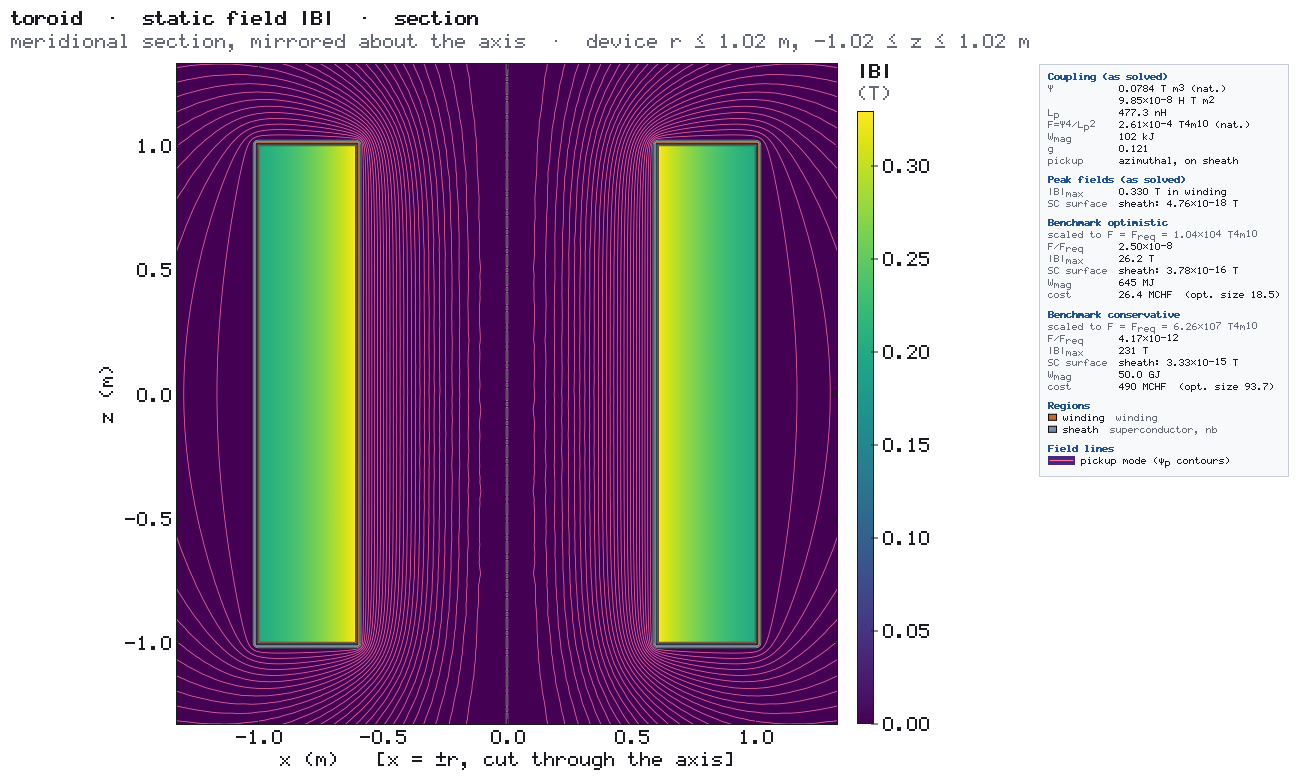

In [3]:
display(Image(filename=str(res_t.png(RUNS / "toroid_section.png", view="section", quantity="Bmag",
                                     width=1300, height=780)), width=900))

### Results

`coupling` also reports natural Heaviside–Lorentz values: $\Psi$ in $\mathrm{T\,m^3}$, $L_p$ in metres and $\mathcal F$ in $\mathrm{T^4\,m^{10}}$. The flux calculation uses natural $\kappa_a$ in $\mathrm{m^{-1}}$. Unit conventions must remain consistent. Geometric factor `g` uses the radius including walls; it differs from photon coupling. We report coupling and axion flux and compare element orders; the mesh should then be refined before design decisions.

In [4]:
c = res_t.coupling
Psi_n, L_n, W_J, R_dev = c["Psi_natural_T_m3"], c["L_p_natural_m"], c["W_mag_J"], c["device_radius_m"]
print(f"Psi = {c['Psi_SI_H_T_m2']:.4e} H T m^2 = {Psi_n:.4f} T m^3;  L_p = {c['L_p_H']*1e9:.1f} nH = {L_n:.4f} m;  "
      f"F = {c['F_natural_T4_m10']:.4e} T^4 m^10")
print(f"W_mag = {W_J/1e3:.1f} kJ at NI = {tor.resolved_params()['NI']:.0e} A-turns, B_max = {res_t.B_max:.3f} T")
print(f"g = {c['g_factor']:.5f}  (by hand: Psi^2/(L_p W R^2) = {Psi_n**2 / (L_n * MU0 * W_J * R_dev**2):.5f}, R = {R_dev} m)")

# kappa_a for g = 1e-19 GeV^-1, rho = 0.3 GeV/cm^3 (natural units -> m^-1), and the flux it drives
GEV_J, HBARC = 1.602176634e-10, 1.973269804e-7 * 1.602176634e-19        # J/GeV, hbar*c [J m]
kappa_m = 1e-19 / GEV_J * math.sqrt(2 * 0.3 * GEV_J * 1e6 * HBARC)
PHI0 = 2.067833848e-15
print(f"kappa_a(1e-19 GeV^-1) = {kappa_m:.6e} m^-1")
print(f"Phi_a = kappa_a Psi = {kappa_m * Psi_n:.3e} Wb = {kappa_m * Psi_n / PHI0:.2e} Phi_0 at B_max = {res_t.B_max:.2f} T")

print("\norder-3 check (same mesh):")
res_t3 = solve(tor, "toroid_p3", order=3)
for k in ("Psi_SI_H_T_m2", "L_p_H", "F_SI_T4_H2_m8", "W_mag_J", "g_factor"):
    print(f"  {k:15s} p2 {c[k]:.6e}   p3 {res_t3.coupling[k]:.6e}   rel. change {res_t3.coupling[k] / c[k] - 1:+.1e}")

Psi = 9.8475e-08 H T m^2 = 0.0784 T m^3;  L_p = 477.3 nH = 0.3798 m;  F = 2.6140e-04 T^4 m^10
W_mag = 102.1 kJ at NI = 1e+06 A-turns, B_max = 0.330 T
g = 0.12112  (by hand: Psi^2/(L_p W R^2) = 0.12112, R = 1.0199999999999998 m)
kappa_a(1e-19 GeV^-1) = 1.088100e-24 m^-1
Phi_a = kappa_a Psi = 8.527e-26 Wb = 4.12e-11 Phi_0 at B_max = 0.33 T

order-3 check (same mesh):
  toroid_p3: 179281 DOFs
  Psi_SI_H_T_m2   p2 9.847478e-08   p3 9.847463e-08   rel. change -1.5e-06
  L_p_H           p2 4.772929e-07   p3 4.772934e-07   rel. change +1.1e-06
  F_SI_T4_H2_m8   p2 4.127910e-16   p3 4.127876e-16   rel. change -8.2e-06
  W_mag_J         p2 1.021005e+05   p3 1.021002e+05   rel. change -3.2e-06
  g_factor        p2 1.211204e-01   p3 1.211202e-01   rel. change -8.8e-07


### Length sweep

The sweep compares finite toroids with their long limit; finite walls change that limit.

We vary the toroid length and extrapolate its geometric factor to check the long limit.

In [5]:
def g_long_toroid(p, R_dev):
    """Long-limit g of the toroid template's cross-section (walls of finite thickness, uniform J in the legs)."""
    y, R, tw = p["y"], p["R"], p["tw"]
    r1, r2 = y * R - tw, y * R
    def B(r):                                  # B_phi(r) up to a constant
        if r1 <= r < r2: return (r * r - r1 * r1) / (r2 * r2 - r1 * r1) / r
        if r2 <= r < R: return 1.0 / r
        if R <= r < R + tw: return (1.0 - (r * r - R * R) / ((R + tw) ** 2 - R * R)) / r
        return 0.0
    edges = [r1, r2, R, R + tw]
    I1 = sum(quad(B, a, b)[0] for a, b in zip(edges[:-1], edges[1:]))
    I2 = sum(quad(lambda r: B(r) ** 2 * r, a, b)[0] for a, b in zip(edges[:-1], edges[1:]))
    r_i = y * R - tw - p["g"] - p["ts"]
    return r_i ** 2 * I1 ** 2 / (I2 * R_dev ** 2), dict(I1=I1, I2=I2, r_i=r_i)

HR = np.array([1, 2, 4, 8, 16])
long_t = []
for h in HR:
    d = af.template("toroid", R=1.0, H=float(h))
    d.doc["mesh"]["size"] = "R/12"
    long_t.append(solve(d, f"toroid_H{h}"))
g_t = np.array([r.g for r in long_t])
p_t = af.template("toroid", R=1.0).resolved_params()
g_inf_t, parts_t = g_long_toroid(p_t, long_t[0].coupling["device_radius_m"])
fit_t = np.polyfit(1 / HR[-3:], g_t[-3:], 2)
print(f"\nideal long limit 1/(2e)          = {1 / (2 * math.e):.5f}")
print(f"long limit of this cross-section = {g_inf_t:.5f}  (walls: r_i = {parts_t['r_i']:.4f} m, R_dev = {long_t[0].coupling['device_radius_m']} m)")
print(f"FEM, extrapolated to H -> inf    = {fit_t[-1]:.5f}  ({fit_t[-1] / g_inf_t - 1:+.1%})")
for h, r in zip(HR, long_t):
    print(f"  H/R = {h:2d}: g = {r.g:.5f} = {r.g / g_inf_t:.3f} g_inf")

  toroid_H1: 43016 DOFs
  toroid_H2: 72406 DOFs
  toroid_H4: 134583 DOFs
  toroid_H8: 278844 DOFs
  toroid_H16: 685257 DOFs

ideal long limit 1/(2e)          = 0.18394
long limit of this cross-section = 0.17119  (walls: r_i = 0.5865 m, R_dev = 1.0199999999999998 m)
FEM, extrapolated to H -> inf    = 0.17095  (-0.1%)
  H/R =  1: g = 0.09489 = 0.554 g_inf
  H/R =  2: g = 0.12112 = 0.708 g_inf
  H/R =  4: g = 0.14133 = 0.826 g_inf
  H/R =  8: g = 0.15460 = 0.903 g_inf
  H/R = 16: g = 0.16239 = 0.949 g_inf


We plot the geometric factor and normalized coupling, inductance and energy to identify end effects.

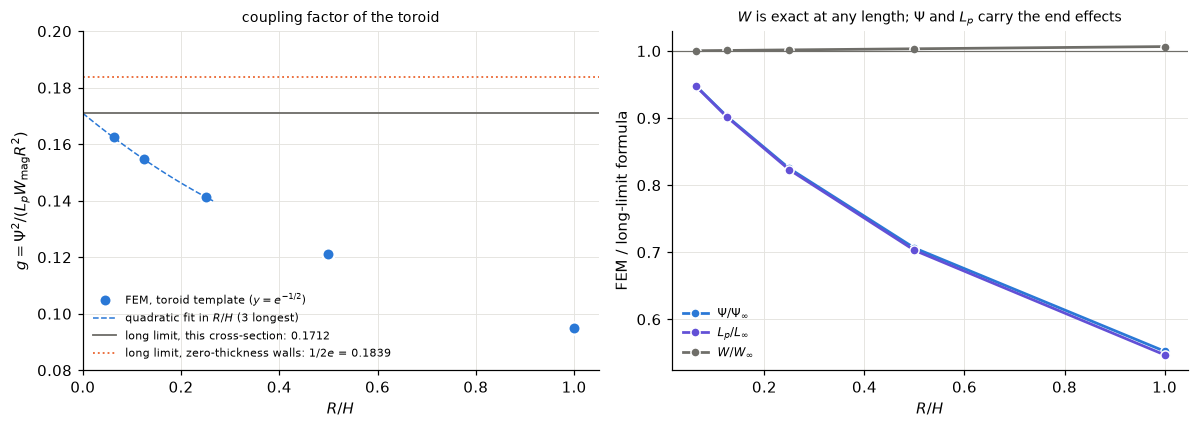

In [6]:
# The long-limit Psi, L and W of the same cross-section (per ampere-turn, SI), to see which quantity carries the end effects
NI = p_t["NI"]
B0 = MU0 * NI / (2 * math.pi)                       # B_phi = B0 * B(r) of g_long_toroid
ratios = {"$\\Psi/\\Psi_\\infty$": [], "$L_p/L_\\infty$": [], "$W/W_\\infty$": []}
for h, r in zip(HR, long_t):
    cc = r.coupling
    ratios["$\\Psi/\\Psi_\\infty$"].append(cc["Psi_natural_T_m3"] / (math.pi * parts_t["r_i"] ** 2 * B0 * parts_t["I1"]))
    ratios["$L_p/L_\\infty$"].append(cc["L_p_H"] / (MU0 * math.pi * parts_t["r_i"] ** 2 / h))
    ratios["$W/W_\\infty$"].append(cc["W_mag_J"] / (math.pi * h * B0 ** 2 * parts_t["I2"] / MU0))

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4))
x = np.linspace(0, 1.05, 100)
ax0.plot(1 / HR, g_t, "o", ms=8, color=BLUE, mec="white", mew=1.5, label="FEM, toroid template ($y=e^{-1/2}$)")
ax0.plot(x[x <= 0.27], np.polyval(fit_t, x[x <= 0.27]), color=BLUE, lw=1, ls="--", label="quadratic fit in $R/H$ (3 longest)")
ax0.axhline(g_inf_t, color=GREY, lw=1.2, label=f"long limit, this cross-section: {g_inf_t:.4f}")
ax0.axhline(1 / (2 * math.e), color=ORANGE, lw=1.2, ls=":", label=f"long limit, zero-thickness walls: $1/2e$ = {1/(2*math.e):.4f}")
ax0.set_xlabel("$R/H$"); ax0.set_ylabel(r"$g=\Psi^2/(L_pW_{\rm mag}R^2)$"); ax0.set_xlim(0, 1.05); ax0.set_ylim(0.08, 0.2)
ax0.legend(fontsize=7.5, loc="lower left"); ax0.set_title("coupling factor of the toroid", fontsize=9)
for (lab, v), col in zip(ratios.items(), (BLUE, VIOLET, GREY)):
    ax1.plot(1 / HR, v, "o-", ms=6, color=col, mec="white", label=lab)
ax1.axhline(1, color=GREY, lw=0.8)
ax1.set_xlabel("$R/H$"); ax1.set_ylabel("FEM / long-limit formula"); ax1.legend(fontsize=8)
ax1.set_title(r"$W$ is exact at any length; $\Psi$ and $L_p$ carry the end effects", fontsize=9)
fig.tight_layout(); plt.show()

## Geometry comparison

A solenoid couples an axial field to a coaxial pickup. CORE places a split solenoid inside a superconducting toroidal pickup cavity.

We build and solve solenoid and CORE models for comparison with the toroid.

In [7]:
sol = af.template("solenoid", R=1.0, H=2.0)
core = af.template("core", Rc=0.4, H=2.0)
res_s = solve(sol, "solenoid")
res_c = solve(core, "core")
print(sol.resolved_params())
print({k: round(v, 4) for k, v in core.resolved_params().items()})
designs = {"toroid": (tor, res_t), "solenoid": (sol, res_s), "core": (core, res_c)}

  solenoid: 73566 DOFs
  core: 191118 DOFs
{'H': 2.0, 'NI': 1000000.0, 'R': 1.0, 'g': 0.005, 'tc': 0.005, 'tp': 0.01, 'tw': 0.01, 'x': 0.534}
{'H': 2.0, 'NI': 1000000.0, 'Rc': 0.4, 'a': 0.432, 'b': 1.0, 'cl': 0.02, 'f': 0.02, 'fl': 0.0012, 'gc': 0.008, 'gn': 0.004, 'h': 2.0, 'iron_dz': 0.008, 'iron_r0': 0.0, 'iron_r1': 1.004, 'iron_t': 0.0, 'tw': 0.008, 'w': 0.004}


We plot the solenoid and CORE cross-sections to compare their static and pickup fields.

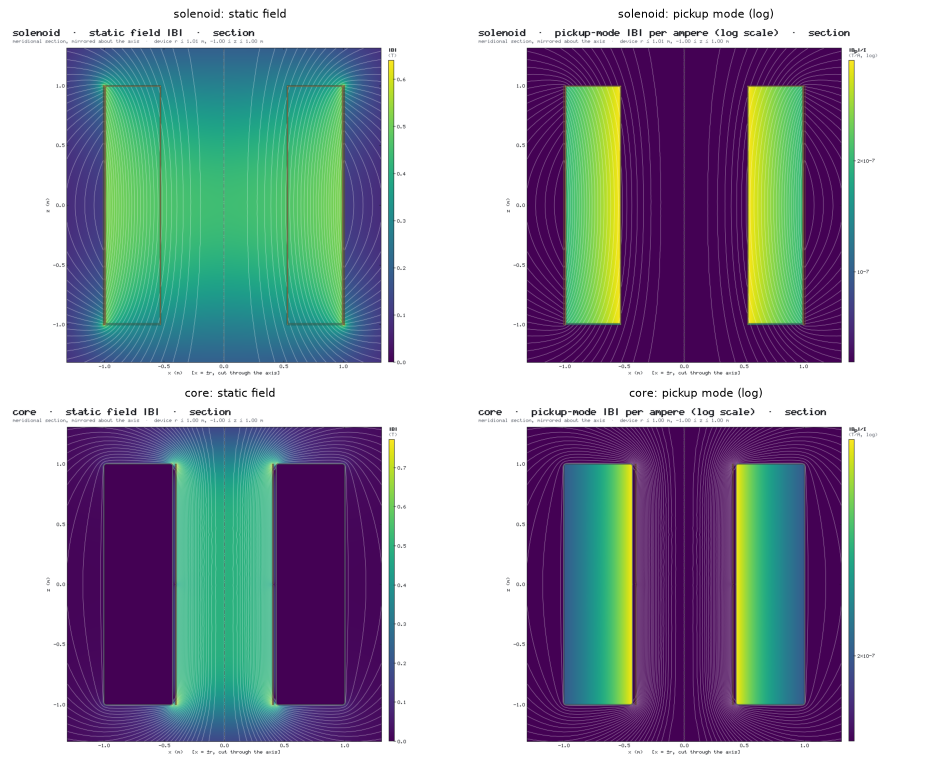

In [8]:
fig, axs = plt.subplots(2, 2, figsize=(10.5, 8.6), dpi=90)
for row, name in zip(axs, ("solenoid", "core")):
    r = designs[name][1]
    for ax, (q, log, lab) in zip(row, (("Bmag", False, "static field"), ("pickup_Bmag", True, "pickup mode (log)"))):
        p = r.png(RUNS / f"{name}_{q}.png", view="section", quantity=q, log_scale=log, width=900, height=720, annotate=False)
        ax.imshow(plt.imread(p)); ax.axis("off"); ax.set_title(f"{name}: {lab}", fontsize=9)
fig.tight_layout(); plt.show()

Static fields are on the left, pickup fields on the right.

### Comparison results

The table reports coupling, inductance, energy and required amplitude. Regular surface peaks exclude sharp-corner neighborhoods.

We tabulate coupling and field requirements to compare the three geometries.

In [9]:
def g_long(name, p):
    if name == "solenoid":
        x = p["x"]; return (1 - x * x) ** 2 / (4 * math.log(1 / x))
    y = p["y"] if name == "toroid" else p["a"] / p["b"]
    return y * y * math.log(1 / y)

rows = []
print(f"{'':9s}{'Psi [T m^3]':>12s}{'L_p [nH]':>10s}{'F [T^4m^10]':>13s}{'W [kJ]':>9s}{'g':>8s}{'g_long':>8s}{'R_dev':>7s}")
for name, (d, r) in designs.items():
    cc = r.coupling
    print(f"{name:9s}{cc['Psi_natural_T_m3']:12.4f}{cc['L_p_H']*1e9:10.1f}{cc['F_natural_T4_m10']:13.4e}{cc['W_mag_J']/1e3:9.1f}"
          f"{r.g:8.4f}{g_long(name, d.resolved_params()):8.4f}{cc['device_radius_m']:7.3f}")
print()
print(f"{'':9s}{'benchmark':>22s}{'F/F_req':>11s}{'ampl. x':>9s}{'B_max@req':>11s}{'SC surface@req':>16s}")
for name, (d, r) in designs.items():
    for b in r.data["benchmarks"]:
        sc = b["superconductor_surface_regular_at_req_T"]
        print(f"{name:9s}{b['name']:>22s}{b['F_over_F_req']:11.3e}{b['amplitude_scale']:9.1f}{b['B_max_at_req_T']:9.1f} T"
              f"{(f'{max(sc.values()):12.3g} T') if sc else '        (none)':>16s}")
fc = res_c.data["fields"]
print(f"\nCORE as solved: peak |B| on the cavity {fc['superconductor_surface_T']['cavity']:.3f} T at "
      f"{ {k: round(v, 3) for k, v in fc['superconductor_surface_location']['cavity'].items()} } "
      f"(cavity inner radius a = {core.resolved_params()['a']} m, ends at z = +-{core.resolved_params()['h'] / 2} m); "
      f"sharp corners: {fc['superconductor_sharp_corners'] or 'none'}")

          Psi [T m^3]  L_p [nH]  F [T^4m^10]   W [kJ]       g  g_long  R_dev
toroid         0.0784     477.3   2.6140e-04    102.1  0.1211  0.1839  1.020
solenoid       0.1430     245.5   1.0961e-02    681.9  0.1198  0.2036  1.010
core           0.0652     335.7   2.5365e-04    124.4  0.1011  0.1566  1.004

                      benchmark    F/F_req  ampl. x  B_max@req  SC surface@req
toroid               optimistic  2.504e-08     79.5     26.2 T      3.78e-16 T
toroid             conservative  4.174e-12    699.6    230.7 T      3.33e-15 T
solenoid             optimistic  1.050e-06     31.2     20.4 T          (none)
solenoid  conservative_solenoid  1.750e-11    488.9    319.7 T          (none)
core                 optimistic  2.430e-08     80.1     61.9 T          61.9 T
core               conservative  4.050e-12    704.9    544.5 T           545 T

CORE as solved: peak |B| on the cavity 0.772 T at {'r_m': 0.437, 'z_m': -1.001} (cavity inner radius a = 0.43200000000000005 m, ends at z

CORE's ideal Meissner model needs an explicit material field cap when scaling.

### Long-limit comparison

Toroid and CORE exchange static and pickup fields. Length and wall-thickness sweeps separate end and wall effects.

We vary the CORE length and extrapolate its geometric factor to check its long limit.

In [10]:
def g_long_core(p, R_dev):
    """Long-limit g of the CORE template's cross-section (coil of thickness tw with uniform J, cavity a < r < b)."""
    Rc, tw, a, b = p["Rc"], p["tw"], p["a"], p["b"]
    Bz = lambda r: 1.0 if r < Rc else (Rc + tw - r) / tw          # bore, then the winding
    I1 = quad(lambda r: Bz(r) * r, 0, Rc)[0] + quad(lambda r: Bz(r) * r, Rc, Rc + tw)[0]
    I2 = quad(lambda r: Bz(r) ** 2 * r, 0, Rc)[0] + quad(lambda r: Bz(r) ** 2 * r, Rc, Rc + tw)[0]
    return 2 * math.log(b / a) * I1 ** 2 / (I2 * R_dev ** 2)

E12 = math.exp(0.5)
long_c = []
for h in HR:
    d = af.template("core", Rc=1.0, H=float(h))
    d.set(b=f"a*{E12!r}")                                  # y = a/b = e^-1/2, as for the toroid
    d.doc["mesh"]["size"] = "Rc/6"
    long_c.append((d, solve(d, f"core_H{h}")))
p_c = long_c[0][0].resolved_params()
g_c = np.array([r.g for _, r in long_c])
g_inf_c = g_long_core(p_c, long_c[0][1].coupling["device_radius_m"])
fit_c = np.polyfit(1 / HR[-3:], g_c[-3:], 2)
print(f"\nCORE: y = a/b = {p_c['a'] / p_c['b']:.4f};  long limit of this cross-section {g_inf_c:.5f};  "
      f"FEM extrapolated {fit_c[-1]:.5f} ({fit_c[-1] / g_inf_c - 1:+.1%})")
for h, (_, r) in zip(HR, long_c):
    print(f"  H/R_c = {h:2d}: g = {r.g:.5f} = {r.g / g_inf_c:.3f} g_inf")

  core_H1: 52327 DOFs
  core_H2: 82053 DOFs
  core_H4: 141852 DOFs
  core_H8: 256313 DOFs
  core_H16: 474214 DOFs

CORE: y = a/b = 0.6065;  long limit of this cross-section 0.16014;  FEM extrapolated 0.15917 (-0.6%)
  H/R_c =  1: g = 0.05830 = 0.364 g_inf
  H/R_c =  2: g = 0.08670 = 0.541 g_inf
  H/R_c =  4: g = 0.11272 = 0.704 g_inf
  H/R_c =  8: g = 0.13222 = 0.826 g_inf
  H/R_c = 16: g = 0.14477 = 0.904 g_inf


We vary wall thickness and plot both geometries' coupling factors to separate end and wall effects.

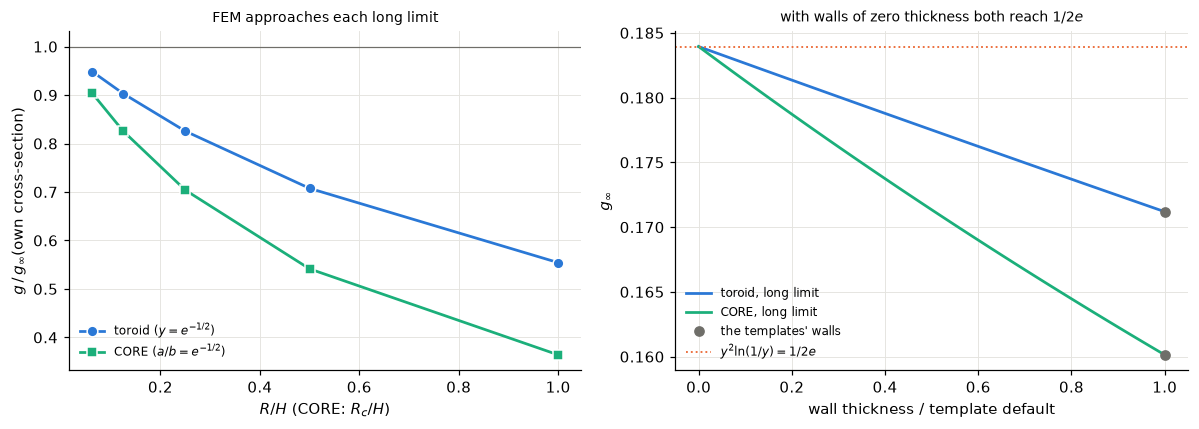

zero walls: toroid 0.183940, CORE 0.183940, 1/(2e) = 0.183940


In [11]:
# shrink every wall of both analytic cross-sections by a factor s -> 0
s_grid = np.linspace(0, 1, 41)
g_ts, g_cs = [], []
for s in s_grid:
    pt = dict(p_t, tw=s * p_t["tw"], g=s * p_t["g"], ts=s * p_t["ts"])
    g_ts.append(g_long_toroid(pt, p_t["R"] + s * (p_t["tw"] + p_t["g"] + p_t["ts"]))[0])
    tw, cl, w = s * p_c["tw"], s * p_c["cl"], s * p_c["w"]
    a = p_c["Rc"] + tw + cl + w
    g_cs.append(g_long_core(dict(p_c, tw=tw, a=a, b=a * E12), a * E12 + w))

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4))
ax0.plot(1 / HR, g_t / g_inf_t, "o-", ms=7, color=BLUE, mec="white", label="toroid ($y=e^{-1/2}$)")
ax0.plot(1 / HR, g_c / g_inf_c, "s-", ms=7, color=GREEN, mec="white", label="CORE ($a/b=e^{-1/2}$)")
ax0.axhline(1, color=GREY, lw=0.8)
ax0.set_xlabel("$R/H$ (CORE: $R_c/H$)"); ax0.set_ylabel(r"$g\,/\,g_\infty$(own cross-section)")
ax0.set_title("FEM approaches each long limit", fontsize=9); ax0.legend(fontsize=8)
ax1.plot(s_grid, g_ts, color=BLUE, label="toroid, long limit")
ax1.plot(s_grid, g_cs, color=GREEN, label="CORE, long limit")
ax1.plot([1, 1], [g_inf_t, g_inf_c], "o", color=GREY, ms=6, label="the templates' walls")
ax1.axhline(1 / (2 * math.e), color=ORANGE, ls=":", lw=1.2, label="$y^2\\ln(1/y)=1/2e$")
ax1.set_xlabel("wall thickness / template default"); ax1.set_ylabel(r"$g_\infty$")
ax1.set_title("with walls of zero thickness both reach $1/2e$", fontsize=9); ax1.legend(fontsize=8)
fig.tight_layout(); plt.show()
print(f"zero walls: toroid {g_ts[0]:.6f}, CORE {g_cs[0]:.6f}, 1/(2e) = {1 / (2 * math.e):.6f}")

## Scan requirements

`requirement` computes $\mathcal F_{\rm req}$. A design with $\mathcal F/\mathcal F_{\rm req}\geq1$ meets the scan target at its specified field. `Q` is resonator quality factor, `T` temperature in kelvin, and `eta_A` amplifier noise. The `optimistic` and `conservative` presets are illustrative; the optimistic one assumes noise below the standard quantum limit. The scan target is the default one, also illustrative: the DFSZ coupling over 120.9 kHz–1 MHz in three years.

We compare benchmark scan requirements with a thermal-limit formula as a consistency check.

In [12]:
EV_PER_K, RHO_EV4 = 8.617333262e-5, 2.305051669e-6          # k_B [eV/K], 0.3 GeV/cm^3 [eV^4]
EV_INV_PER_S, YEAR_S, T4M10_EV2 = 1.519267447e15, 3.15576e7, 1.627097598e76

def F_req_closed(bm, f1=120.9e3, f2=1.0e6, t_yr=3.0, Q_a=6.8e5, Theta=2.71):
    """Thermal-limit scan requirement in natural units, returned in T^4 m^10."""
    m1, m2 = scan.freq_to_mass(f1), scan.freq_to_mass(f2)
    g1 = float(scan.g_qcd([m1])[0]) * 1e-9                         # GeV^-1 -> eV^-1
    F = (3 * math.sqrt(3) / math.pi ** 2 * Theta * bm["eta_A"] * bm["T"] * EV_PER_K
         / (Q_a * bm["Q"] * RHO_EV4 ** 2 * g1 ** 4 * t_yr * YEAR_S * EV_INV_PER_S) * (1 - (m1 / m2) ** 4))
    return F / T4M10_EV2

print(f"{'benchmark':22s}{'Q':>9s}{'T [mK]':>8s}{'eta_A':>7s}{'F_req [T^4 m^10]':>18s}{'closed form':>13s}{'g_DFSZ(m1)':>12s}")
for name, bm in scan.BENCHMARKS.items():
    rq = af.requirement(name)
    print(f"{name:22s}{bm['Q']:9.0e}{bm['T']*1e3:8.0f}{bm['eta_A']:7.1f}{rq['F_req_natural_T4_m10']:18.6e}"
          f"{F_req_closed(bm):13.6e}{rq['g_min_GeV']:12.4e}")

benchmark                     Q  T [mK]  eta_A  F_req [T^4 m^10]  closed form  g_DFSZ(m1)
optimistic                2e+07      10    0.1      1.043768e+04 1.043768e+04  9.1351e-20
conservative              1e+06      30   10.0      6.262608e+07 6.262608e+07  9.1351e-20
conservative_solenoid     1e+05      30   10.0      6.262608e+08 6.262608e+08  9.1351e-20


### Design resizing

A conductor limits the peak field. At the requirement the peak field scales as $\ell^{-5/2}$ with the length scale $\ell$, so the smallest toroid of this shape that reaches the requirement with a peak field of at most $B_{\rm cap}$ has $\ell=(B_{\rm req}/B_{\rm cap})^{2/5}$; $B_{\rm cap}=5\,\mathrm T$ is an illustrative value.

We rebuild and solve the toroid at this size and required current to check that the requirement ratio approaches one.

In [13]:
b_opt = res_t.benchmark("optimistic")
B_cap = 5.0                                               # illustrative peak-field limit [T]
ell, s_amp = (b_opt["B_max_at_req_T"] / B_cap) ** 0.4, b_opt["amplitude_scale"]
p0 = tor.resolved_params()
tor_opt = af.template("toroid", R=p0["R"] * ell, H=p0["H"] * ell)
tor_opt.set(NI=p0["NI"] * s_amp * ell ** -1.5)            # field scale s * ell^-5/2, times ell for the ampere-turns
res_o = solve(tor_opt, "toroid_field_limited")
bo = res_o.benchmark("optimistic")
print(f"length scale {ell:.4f}: R = {tor_opt.resolved_params()['R']:.3f} m, H = {tor_opt.resolved_params()['H']:.3f} m, "
      f"NI = {tor_opt.resolved_params()['NI']:.4e} A-turns")
print(f"F/F_req = {bo['F_over_F_req']:.6f} (target 1);  B_max = {res_o.B_max:.3f} T (cap {B_cap:g} T);  "
      f"W = {res_o.W/1e6:.1f} MJ (predicted {b_opt['W_mag_at_req_J'] * ell ** -2 / 1e6:.1f} MJ)")
PSI_O, L_O = res_o.Psi, res_o.L_p

  toroid_field_limited: 79606 DOFs
length scale 1.9400: R = 1.940 m, H = 3.880 m, NI = 2.9417e+07 A-turns
F/F_req = 1.000000 (target 1);  B_max = 5.000 T (cap 5 T);  W = 171.4 MJ (predicted 171.4 MJ)


### Scan reach

For time allocated to follow target coupling $g_t$, the median expected 95% upper limit is

$$
g_{95}=g_t\left(\frac{t_{\rm req}}{t}\right)^{1/4}
=g_t\left(\frac{\mathcal F_{\rm req}}{\mathcal F}\right)^{1/4}.
$$

$t_{\rm req}$ is the time needed to reach the target throughout the band; $t$ is available live time. `scan.reach` takes SI inputs and returns limits; `squid.benchmark` supplies chain noise. A coupling ratio below one reaches the target. The local scan assumes weak signals, dense tuning, narrow sensitivity bands, and dwell times longer than coherence and ring-up times.

We compute and plot the resized toroid's reach to compare benchmark presets and SQUID chains.

case                                   g95/g_DFSZ  eta_A(120.9 kHz)  time to DFSZ
optimistic (eta_A = 0.1)                    1.000              0.10          3 yr
conservative (eta_A = 10)                   8.801             10.00    1.8e+04 yr
Q = 1e6, 30 mK, C1+low+RT chain             8.736              9.71  1.747e+04 yr
Q = 2e7, 10 mK, C1 alone                    2.467              3.70      111.1 yr


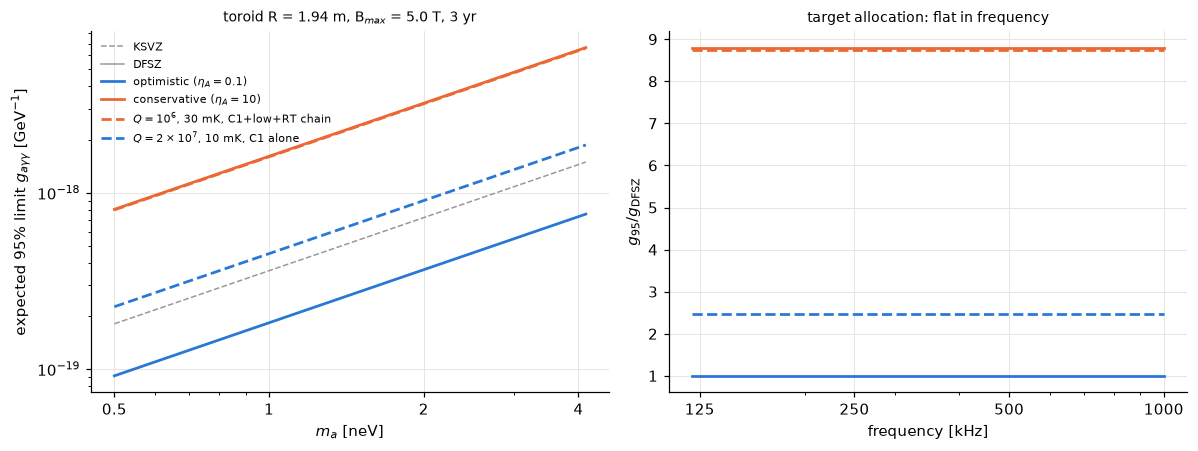

In [14]:
cases = [("optimistic ($\\eta_A=0.1$)", "optimistic (eta_A = 0.1)", "optimistic", BLUE, "-"),
         ("conservative ($\\eta_A=10$)", "conservative (eta_A = 10)", "conservative", ORANGE, "-"),
         ("$Q=10^6$, 30 mK, C1+low+RT chain", "Q = 1e6, 30 mK, C1+low+RT chain",
          squid.benchmark("C1+low+RT", Q=1e6, T_K=0.03), ORANGE, "--"),
         ("$Q=2\\times10^7$, 10 mK, C1 alone", "Q = 2e7, 10 mK, C1 alone",
          squid.benchmark("C1", Q=2e7, T_K=0.01), BLUE, "--")]
reach = {lab: scan.reach(PSI_O, L_O, bm, n=60) for lab, _, bm, _, _ in cases}

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4.2))
ref = next(iter(reach.values()))
m_neV = ref["m_eV"] * 1e9
ax0.plot(m_neV, scan.g_qcd(ref["m_eV"], "KSVZ"), color="0.6", lw=1, ls="--", label="KSVZ")
ax0.plot(m_neV, ref["g_target_GeV"], color="0.6", lw=1, label="DFSZ")
print(f"{'case':38s}{'g95/g_DFSZ':>11s}{'eta_A(120.9 kHz)':>18s}{'time to DFSZ':>14s}")
for lab, txt, bm, col, ls in cases:
    r = reach[lab]
    ratio = r["g95_GeV"] / r["g_target_GeV"]
    ax0.plot(r["m_eV"] * 1e9, r["g95_GeV"], color=col, ls=ls, label=lab)
    ax1.plot(r["f_Hz"] / 1e3, ratio, color=col, ls=ls, label=lab)
    eta0 = np.atleast_1d(r["band"]["eta_A"])[0]
    print(f"{txt:38s}{np.median(ratio):11.3f}{eta0:18.2f}{3 * np.median(ratio) ** 4:11.4g} yr")
ax0.set_xscale("log"); ax0.set_yscale("log"); ax0.set_xlabel("$m_a$ [neV]")
ax0.set_xticks([0.5, 1, 2, 4]); ax0.set_xticklabels(["0.5", "1", "2", "4"]); ax0.xaxis.set_minor_formatter(plt.NullFormatter())
ax0.set_ylabel(r"expected 95% limit $g_{a\gamma\gamma}$ [GeV$^{-1}$]")
ax0.set_title(f"toroid R = {tor_opt.resolved_params()['R']:.2f} m, B$_{{max}}$ = {res_o.B_max:.1f} T, 3 yr", fontsize=9)
ax0.legend(fontsize=7.5)
ax1.set_xscale("log"); ax1.set_xlabel("frequency [kHz]")
ax1.set_xticks([125, 250, 500, 1000]); ax1.set_xticklabels(["125", "250", "500", "1000"]); ax1.xaxis.set_minor_formatter(plt.NullFormatter()); ax1.set_ylabel(r"$g_{95}/g_{\rm DFSZ}$")
ax1.set_title("target allocation: flat in frequency", fontsize=9)
fig.tight_layout(); plt.show()

### Size sweep

At fixed shape and with the detector held at the requirement, the stored energy scales as $\ell^{-2}$ and the peak field as $\ell^{-5/2}$: a larger magnet of the same shape reaches the same sensitivity with less energy and a lower field.

We solve toroids at several sizes to check the energy and field scaling laws.

  toroid_R0.5: 79774 DOFs
  toroid_R0.8: 79802 DOFs
  toroid_R1.25: 79674 DOFs
  toroid_R2: 79774 DOFs
  toroid_R3.2: 79802 DOFs
  toroid_R5: 79674 DOFs
 R [m]  W@req [MJ]     W law  B_max@req [T]    B law
  0.50        2581      2581          148.3    148.3
  0.80        1008      1008          45.79    45.79
  1.25       412.9     412.9             15       15
  2.00       161.3     161.3          4.634    4.634
  3.20          63        63          1.431    1.431
  5.00       25.81     25.81         0.4689   0.4689


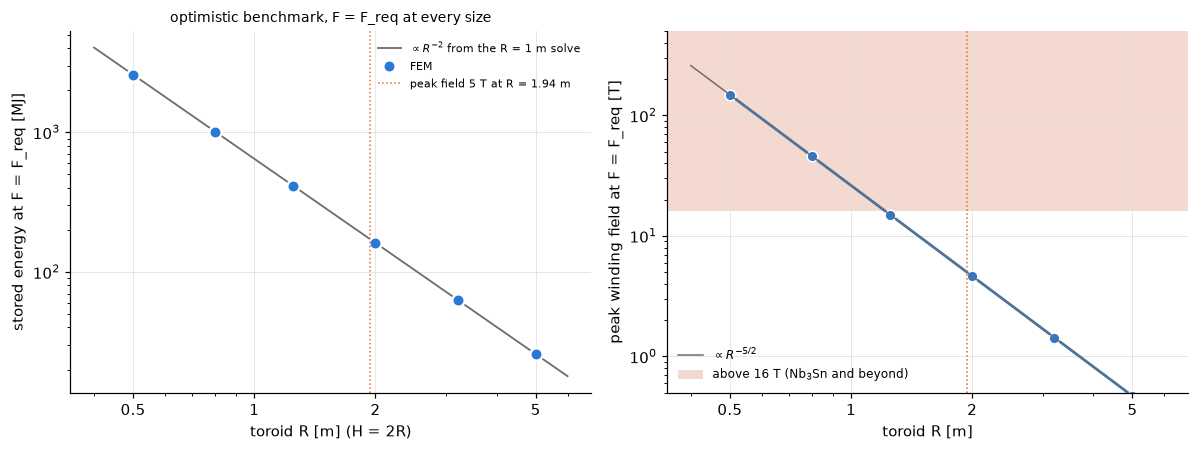

In [15]:
sizes = np.array([0.5, 0.8, 1.25, 2.0, 3.2, 5.0])
scan_rows = []
for Rs in sizes:
    r = solve(af.template("toroid", R=float(Rs), H=2.0 * Rs), f"toroid_R{Rs:g}")
    b = r.benchmark("optimistic")
    scan_rows.append((Rs, b["W_mag_at_req_J"], b["B_max_at_req_T"]))
scan_rows = np.array(scan_rows)

# the scaling laws from the R = 1 m solve alone
l = np.geomspace(0.4, 6, 200)
R_cap = tor_opt.resolved_params()["R"]

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4.2))
ax0.plot(l, b_opt["W_mag_at_req_J"] * l ** -2 / 1e6, color=GREY, lw=1.2, label=r"$\propto R^{-2}$ from the R = 1 m solve")
ax0.plot(scan_rows[:, 0], scan_rows[:, 1] / 1e6, "o", ms=8, color=BLUE, mec="white", mew=1.5, label="FEM")
ax0.axvline(R_cap, color=ORANGE, lw=1, ls=":", label=f"peak field {B_cap:g} T at R = {R_cap:.2f} m")
ax0.set_xscale("log"); ax0.set_yscale("log"); ax0.set_xlabel("toroid R [m] (H = 2R)")
ax0.set_ylabel("stored energy at F = F_req [MJ]")
ax0.set_title("optimistic benchmark, F = F_req at every size", fontsize=9); ax0.legend(fontsize=7.5)
ax1.plot(scan_rows[:, 0], scan_rows[:, 2], "o-", ms=7, color=BLUE, mec="white")
ax1.plot(l, b_opt["B_max_at_req_T"] * l ** -2.5, color=GREY, lw=1, label=r"$\propto R^{-5/2}$")
ax1.axhspan(16, 1e3, color="#f3d9d0", lw=0, label="above 16 T (Nb$_3$Sn and beyond)")
ax1.axvline(R_cap, color=ORANGE, lw=1, ls=":")
ax1.set_xscale("log"); ax1.set_yscale("log"); ax1.set_ylim(0.5, 500)
for ax in (ax0, ax1):
    ax.set_xticks([0.5, 1, 2, 5]); ax.set_xticklabels(["0.5", "1", "2", "5"]); ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax1.set_xlabel("toroid R [m]"); ax1.set_ylabel("peak winding field at F = F_req [T]"); ax1.legend(fontsize=8)
fig.tight_layout(); plt.show()
print(f"{'R [m]':>6s}{'W@req [MJ]':>12s}{'W law':>10s}{'B_max@req [T]':>15s}{'B law':>9s}")
for Rs, W, B in scan_rows:
    print(f"{Rs:6.2f}{W / 1e6:12.4g}{b_opt['W_mag_at_req_J'] * Rs ** -2 / 1e6:10.4g}{B:15.4g}{b_opt['B_max_at_req_T'] * Rs ** -2.5:9.4g}")

### Scan band

These resizing laws assume linear MQS models without iron or active field caps.

We vary the scan band to check how the requirement, the field-limited size and its stored energy scale: $\mathcal F_{\rm req}\propto m_1^{-4}$, and at a fixed peak field $\ell\propto\mathcal F_{\rm req}^{1/10}$ and $W\propto\mathcal F_{\rm req}^{3/10}$.

In [16]:
f1s = np.array([30e3, 60e3, 120.9e3, 240e3, 480e3])
ss = []
for f1 in f1s:
    d = tor.copy()
    d.doc["scan"] = {"f_min": float(f1), "f_max": float(f1 * 991.4 / 120.9)}
    b = solve(d, f"toroid_fmin{f1/1e3:g}k").benchmark("optimistic")
    l_ = (b["B_max_at_req_T"] / B_cap) ** 0.4                   # field-limited length scale
    ss.append((b["F_req_natural_T4_m10"], l_, b["W_mag_at_req_J"] * l_ ** -2))
ss = np.array(ss)
m1 = np.array([scan.freq_to_mass(f) for f in f1s])
slope = lambda x, y: np.polyfit(np.log(x), np.log(y), 1)[0]
print(f"{'f_min [kHz]':>12s}{'m1 [neV]':>10s}{'F_req':>12s}{'l':>8s}{'W [MJ]':>10s}")
for f1, m, (F, l_, W) in zip(f1s, m1, ss):
    print(f"{f1/1e3:12.1f}{m*1e9:10.3f}{F:12.4e}{l_:8.3f}{W / 1e6:10.2f}")
print(f"\nd ln F_req / d ln m1 = {slope(m1, ss[:, 0]):+.5f}   (expected -4)")
print(f"d ln l     / d ln F_req = {slope(ss[:, 0], ss[:, 1]):+.5f}   (expected 1/10)")
print(f"d ln W     / d ln F_req = {slope(ss[:, 0], ss[:, 2]):+.5f}   (expected 3/10)")

# with f_max held at 1 MHz instead, the bracket [1 - (m1/m2)^4] breaks the pure power law slightly
Fq = np.array([af.requirement("optimistic", f_min=float(f), f_max=1e6)["F_req_natural_T4_m10"] for f in f1s])
print(f"\nf_max fixed at 1 MHz: d ln F_req / d ln m1 = {slope(m1, Fq):+.4f}")

  toroid_fmin30k: 79774 DOFs
  toroid_fmin60k: 79774 DOFs
  toroid_fmin120.9k: 79774 DOFs
  toroid_fmin240k: 79774 DOFs
  toroid_fmin480k: 79774 DOFs
 f_min [kHz]  m1 [neV]       F_req       l    W [MJ]
        30.0     0.124  2.7531e+06   3.388    912.88
        60.0     0.248  1.7207e+05   2.568    397.36
       120.9     0.500  1.0438e+04   1.940    171.42
       240.0     0.993  6.7214e+02   1.475     75.28
       480.0     1.985  4.2009e+01   1.118     32.77

d ln F_req / d ln m1 = -4.00000   (expected -4)
d ln l     / d ln F_req = +0.10000   (expected 1/10)
d ln W     / d ln F_req = +0.30000   (expected 3/10)

f_max fixed at 1 MHz: d ln F_req / d ln m1 = -4.0162


## COMSOL export

axionFEM's COMSOL export includes geometry and selections; the commented 3D solve requires MPI.

We export the resized toroid as a Java file for use in COMSOL.

In [17]:
from axionfem import comsol
out = comsol.export_comsol(tor_opt, str(RUNS / "ToroidFieldLimited.java"), format="java")
print(Path(out["file"]).name, {k: out[k] for k in ("class", "selections", "dimension", "approximations")})

ToroidFieldLimited.java {'class': 'ToroidFieldLimited', 'selections': ['air', 'sheath', 'winding'], 'dimension': 2, 'approximations': ['domain radius not given: 2.5 x estimated device radius (6.99628 m); set mesh.domain_radius for the exact value']}


We outline how to convert and solve the toroid in 3D to include a real slit and port.

In [18]:
# 3D: not run here (MPI build, minutes, several GB). The toroid with a real slit and port:
# from axionfem.convert import to_3d
# d3 = to_3d(tor, pickup="slit", mesh={"size": 0.2, "surface_size": 0.07, "order": 1})
# res3 = d3.solve(RUNS / "toroid_3d", verbose=1)
# print(res3.summary())

Further topics include [readout and multi-band scans](../docs/guides/readout_multiband.md), [SQUID chains](squid_chain_demo.ipynb), [shape optimization](../docs/guides/optimization.md), and [COMSOL](../docs/guides/comsol.md).